# Simulación meteorológica paralela

| | |
|---|---|
| **Alumno** | Diego Navarro Sánchez |
| **No. de cuenta** | 202497 |
| **Materia** | Lenguajes de Computación |
| **Profesor(a)** | Paulo Vázquez |
| **Institución** | Universidad Iberoamericana Puebla |
| **Fecha** | 19 de noviembre de 2026 |

## Revisión del código base

Al ejecutar el código proporcionado aparecen estos errores. Se corrigieron en las fases
siguientes; cada corrección está marcada en el código con `# CORRECCIÓN`.

| Fase | Línea original | Problema | Corrección |
|---|---|---|---|
| 1 | `global_rows = subgrid_rows * pert` | No usa el índice del proceso: **todas las franjas se inicializaban igual**, como si fueran la primera | Fila global = `inicio_del_proceso + r` |
| 1 | `grid[r, c]` con `c in range(cols)` | Escribe en la columna fantasma 0 y deja vacía la última columna real | Escribir en las columnas `1..cols` |
| 1 | `N // n_proc` | Si N no es divisible entre P se pierden filas (500 / 8 → se pierden 4) | Las filas sobrantes se reparten entre los primeros procesos |
| 1 | doble `for` en Python | Lento: 250 000 iteraciones con N = 500 | Mismo cálculo vectorizado con NumPy |
| 2 | `grid[0,0] = grid[1, :]` | `ValueError`: asigna una fila completa a una sola celda. Además, la condición estaba invertida | Si **no** hay vecino (`is None`) se copia la fila: frontera de flujo cero |
| 2 | `send` → `recv` en todos | Con mensajes de más de ≈ 64 KB (franjas anchas) **todos envían a la vez y se bloquean** | Orden par/impar: en cada pareja uno envía primero y el otro recibe primero |
| 3 | `grid[0:subgrid_rows, 1:cols-1]`, etc. | `ValueError`: las rebanadas tienen 98 y 100 columnas, no coinciden | Las 4 vecinas usan `1:cols+1`, `0:cols` y `2:cols+2` |
| 4 | `historico.append(step, ...)` | `TypeError`: `append` recibe un solo argumento | `historico.append((step, ...))` |
| 4 | — | El trabajador no recibe su índice (`rank`), no mide tiempos y no hay código que lance los procesos | Se agregan `rank`, medición con `time.perf_counter()` y la Fase 5 de orquestación |

Para responder la pregunta sobre el ancho de las Ghost Cells, las funciones aceptan además
un parámetro **`g`** (filas fantasma por lado, **1 por defecto** como en el original). Para
la pregunta de la tormenta aceptan una zona con **carga de cálculo extra**.

El código de cada fase se guarda en `sim_meteo.py` con `%%writefile`. Así
`multiprocessing` funciona también en Windows/macOS, donde los procesos hijos deben
importar las funciones desde un archivo.

## Fase 1. Particionamiento

Se requiere la segmentación del espacio de soluciones (el espacio de simulación), donde una
región meteorológica está definida por un espacio bidimensional *N × N* dividido en P
franjas horizontales de ≈ *N/P × N*. Cada proceso almacena su franja en una matriz local
(temperatura / presión atmosférica), lo que aprovecha mejor la memoria caché.

In [1]:
%%writefile sim_meteo.py
import time
import numpy as np
from multiprocessing import Pipe, Process


def reparto_filas(N, n_proc, rank):
    """Devuelve (fila_inicial, num_filas) del proceso `rank`.
    CORRECCIÓN: las N % n_proc filas sobrantes se reparten entre los primeros procesos."""
    base, resto = divmod(N, n_proc)
    filas = base + (1 if rank < resto else 0)
    inicio = rank * base + min(rank, resto)
    return inicio, filas


# Asignación de cada proceso en una franja del dominio global
def inicializacion_subdominio(n_proc, N, pert=1.01, rank=0, g=1, franja=None):
    """Crea la matriz local del proceso `rank` con g filas fantasma arriba y abajo y una
    columna fantasma a cada lado. `franja` = (inicio, filas) permite un reparto distinto
    al uniforme (se usa en el balanceo de carga)."""
    inicio, subgrid_rows = franja if franja else reparto_filas(N, n_proc, rank)
    cols = N
    # Matriz local con bordes extra (ghost cells)
    grid = np.zeros((subgrid_rows + 2 * g, cols + 2), dtype=np.float64)
    # Perturbación inicial centrada en (50, 50)
    # CORRECCIÓN: la fila global depende de la posición del proceso (inicio + r)
    # CORRECCIÓN: vectorizado y escrito en las columnas reales 1..cols
    gr = inicio + np.arange(subgrid_rows)[:, None]
    c = np.arange(cols)[None, :]
    dist = np.sqrt((gr - 50) ** 2 + (c - 50) ** 2)
    grid[g:g + subgrid_rows, 1:cols + 1] = 100 * pert * np.exp(-dist / 120)
    return grid, subgrid_rows, cols

Overwriting sim_meteo.py


## Fase 2. Comunicación

Las celdas del límite de cada subdominio necesitan, en el paso *t + 1*, los valores de los
vecinos que pertenecen a otro proceso. Para no acceder a la memoria de otro proceso se
agregan filas adicionales (*ghost cells*): antes de calcular, los procesos vecinos
**intercambian sus bordes por un `Pipe`**.

Con `g` filas fantasma se envían las `g` filas frontera, y el intercambio solo hace falta
**cada g pasos** (ver Fase 4).

In [2]:
%%writefile -a sim_meteo.py
# Intercambio de bordes con los vecinos del Norte (arriba) y del Sur (abajo)
def intercambio_ghost_cells(grid, subgrid_rows, pipe_top, pipe_bottom, g=1, rank=0):
    """Envía las g filas frontera propias y recibe las g filas fantasma de cada vecino.
    Devuelve (bytes_enviados, mensajes)."""
    h = subgrid_rows
    enviados = mensajes = 0
    # CORRECCIÓN: orden par/impar para evitar interbloqueo con mensajes grandes.
    # Fase A: parejas (0,1), (2,3)...  Fase B: parejas (1,2), (3,4)...
    lados = ("sur", "norte") if rank % 2 == 0 else ("norte", "sur")
    for lado in lados:
        conn = pipe_bottom if lado == "sur" else pipe_top
        if conn is None:
            continue
        if lado == "sur":       # mis últimas g filas → vecino del Sur
            borde = grid[h:h + g, :].copy()
            conn.send(borde)                   # el de arriba de la pareja envía primero
            grid[h + g:h + 2 * g, :] = conn.recv()
        else:                   # mis primeras g filas → vecino del Norte
            borde = grid[g:2 * g, :].copy()
            recibido = conn.recv()             # el de abajo de la pareja recibe primero
            conn.send(borde)
            grid[0:g, :] = recibido
        enviados += borde.nbytes
        mensajes += 1
    return enviados, mensajes


def aplicar_fronteras(grid, subgrid_rows, es_borde_norte, es_borde_sur, g=1):
    """Modificación de condiciones físicas en los bordes del dominio GLOBAL.
    CORRECCIÓN: el original hacía `grid[0,0] = grid[1,:]` (ValueError) y solo cuando SÍ
    había vecino. La frontera se aplica cuando NO hay vecino: la fila fantasma copia a la
    fila real (flujo cero a través del borde)."""
    if es_borde_norte:
        grid[g - 1, :] = grid[g, :]
    if es_borde_sur:
        grid[g + subgrid_rows, :] = grid[g + subgrid_rows - 1, :]

Appending to sim_meteo.py


## Fase 3. Agrupamiento y replicación

Una vez actualizadas las *ghost cells*, cada proceso ejecuta la simulación física de su
franja de forma independiente y en paralelo. El esquema es el de Jacobi: cada celda pasa a
ser el promedio de sus 4 vecinas (Norte, Sur, Oeste, Este).

**Tormenta:** en las celdas marcadas como tormenta se resuelve además la convección con
`sub_pasos` sub-iteraciones extra. Esto multiplica la carga de cálculo en ese subdominio.

In [3]:
%%writefile -a sim_meteo.py
# Actualización de las temperaturas/presión atmosférica
def calcular_paso_atmosferico(grid, f0, f1, cols, tormenta=None, sub_pasos=1):
    """Calcula el paso t+1 de las filas locales [f0, f1) con el esténcil de 5 puntos.
    El original actualizaba siempre las filas 1..subgrid_rows; aquí el rango se recibe
    como parámetro para soportar franjas de ghost cells de ancho g."""
    grid_next = grid.copy()
    # CORRECCIÓN: las cuatro rebanadas deben tener (f1-f0) x cols elementos
    grid_next[f0:f1, 1:cols + 1] = 0.25 * (
        grid[f0 - 1:f1 - 1, 1:cols + 1] +   # vecino del Norte
        grid[f0 + 1:f1 + 1, 1:cols + 1] +   # vecino del Sur
        grid[f0:f1, 0:cols] +               # vecino del Oeste
        grid[f0:f1, 2:cols + 2]             # vecino del Este
    )
    # Tormenta: convección resuelta con sub-iteraciones solo en las celdas afectadas
    if tormenta is not None and sub_pasos > 1:
        m = tormenta[f0:f1]
        if m.any():
            filas = np.nonzero(m.any(axis=1))[0]
            a, b = f0 + filas[0], f0 + filas[-1] + 1
            zona = grid_next[a:b, 1:cols + 1]
            mz = tormenta[a:b]
            for _ in range(sub_pasos - 1):
                zona = np.where(mz, zona + 1e-4 * np.sin(zona) * np.exp(-zona / 200), zona)
            grid_next[a:b, 1:cols + 1] = zona
    return grid_next

Appending to sim_meteo.py


## Fase 4. Integración

Se coordina el trabajo de cada *worker* (proceso) en un ciclo SPMD: intercambio de bordes,
cálculo y, opcionalmente, muestreo periódico del campo para visualizarlo. Se mide por
separado el tiempo de **cómputo** y el de **comunicación**.

Con `g > 1` las ghost cells se intercambian cada `g` pasos. En cada paso intermedio la
zona válida se encoge una fila, así que se calcula de forma redundante parte de la franja
del vecino a cambio de enviar menos mensajes.

In [4]:
%%writefile -a sim_meteo.py
# Ciclo principal SPMD que orquesta comunicación y cómputo
def worker_spmd(num_proc, N, steps, pipe_top, pipe_bottom, result_pipe, pertubacion=1.01,
                rank=0, g=1, tormenta_global=None, sub_pasos=1, franjas=None,
                guardar_historico=False):
    franja = franjas[rank] if franjas else None
    grid, subgrid_rows, cols = inicializacion_subdominio(num_proc, N, pertubacion, rank, g,
                                                         franja)
    inicio = franja[0] if franja else reparto_filas(N, num_proc, rank)[0]
    h, H = subgrid_rows, subgrid_rows + 2 * g
    assert h >= g, "cada franja necesita al menos g filas propias"
    norte, sur = pipe_top is None, pipe_bottom is None     # ¿borde del dominio global?

    # Máscara local de tormenta (con las mismas filas fantasma que grid)
    tormenta = None
    if tormenta_global is not None:
        tormenta = np.zeros((H, cols), dtype=bool)
        a, b = max(inicio - g, 0), min(inicio + h + g, N)
        tormenta[a - (inicio - g):b - (inicio - g)] = tormenta_global[a:b]

    historico, muestreo = [], (steps // 10 if steps > 10 else 1)
    t_comp = t_com = 0.0
    enviados = mensajes = 0
    step = 0
    while step < steps:
        # Comunicación de bordes (cada g pasos)
        t0 = time.perf_counter()
        b, m = intercambio_ghost_cells(grid, h, pipe_top, pipe_bottom, g, rank)
        enviados += b; mensajes += m
        t_com += time.perf_counter() - t0
        # Cómputo numérico: hasta g pasos con la zona válida encogiéndose
        t0 = time.perf_counter()
        for s in range(1, min(g, steps - step) + 1):
            aplicar_fronteras(grid, h, norte, sur, g)
            f0 = g if norte else s
            f1 = g + h if sur else H - s
            grid = calcular_paso_atmosferico(grid, f0, f1, cols, tormenta, sub_pasos)
            # Muestreo periódico para visualización del fenómeno atmosférico
            if guardar_historico and step % muestreo == 0:
                # CORRECCIÓN: append recibe una tupla (paso, campo)
                historico.append((step, grid[g:g + h, 1:cols + 1].copy()))
            step += 1
        t_comp += time.perf_counter() - t0

    resultado = {"rank": rank, "final": grid[g:g + h, 1:cols + 1].copy(),
                 "historico": historico, "t_comp": t_comp, "t_com": t_com,
                 "bytes": enviados, "mensajes": mensajes}
    if result_pipe is None:          # ejecución secuencial en el proceso principal
        return resultado
    # Enviar el registro histórico y las métricas al proceso principal
    result_pipe.send(resultado)
    result_pipe.close()

Appending to sim_meteo.py


## Fase 5. Orquestación y medición (agregada)

El código base no incluía la parte que crea los procesos y los pipes. `ejecutar_simulacion`:

1. Crea un `Pipe` entre cada par de franjas vecinas y uno de cada *worker* al proceso
   principal.
2. Lanza P procesos con `worker_spmd`. Con **P = 1** se ejecuta en el proceso principal, sin
   pipes: es la versión **secuencial T₁**.
3. Recolecta las franjas, arma la malla global y mide el **tiempo total de pared** con
   `time.perf_counter()` (creación de procesos + intercambios + cálculo + recolección).

In [5]:
%%writefile -a sim_meteo.py
def ejecutar_simulacion(num_proc, N, steps, g=1, pertubacion=1.01, zona_tormenta=None,
                        sub_pasos=1, franjas=None, guardar_historico=False):
    """Ejecuta la simulación con num_proc procesos. Devuelve (malla_final, métricas, historico).
    zona_tormenta = (fila0, fila1, col0, col1) en fracciones de N."""
    t_inicio = time.perf_counter()
    tormenta = None
    if zona_tormenta is not None:
        tormenta = np.zeros((N, N), dtype=bool)
        f0, f1, c0, c1 = (int(round(z * N)) for z in zona_tormenta)
        tormenta[f0:f1, c0:c1] = True
    if franjas is not None:
        num_proc = len(franjas)
    args = dict(pertubacion=pertubacion, g=g, tormenta_global=tormenta,
                sub_pasos=sub_pasos, franjas=franjas, guardar_historico=guardar_historico)

    if num_proc == 1:
        res = [worker_spmd(1, N, steps, None, None, None, rank=0, **args)]
    else:
        vecinos = [Pipe() for _ in range(num_proc - 1)]          # (i) ↔ (i+1)
        al_maestro = [Pipe(duplex=False) for _ in range(num_proc)]
        procesos = []
        for r in range(num_proc):
            top = vecinos[r - 1][1] if r > 0 else None
            bottom = vecinos[r][0] if r < num_proc - 1 else None
            pr = Process(target=worker_spmd, args=(num_proc, N, steps, top, bottom,
                                                   al_maestro[r][1]),
                         kwargs=dict(rank=r, **args))
            pr.start()
            procesos.append(pr)
        res = [al_maestro[r][0].recv() for r in range(num_proc)]
        for pr in procesos:
            pr.join()

    res.sort(key=lambda x: x["rank"])
    malla = np.vstack([x["final"] for x in res])
    historico = None
    if guardar_historico:
        historico = [(paso, np.vstack([x["historico"][i][1] for x in res]))
                     for i, (paso, _) in enumerate(res[0]["historico"])]
    metricas = {"t_total": time.perf_counter() - t_inicio,
                "por_proceso": [{k: x[k] for k in ("t_comp", "t_com", "bytes", "mensajes")}
                                for x in res]}
    return malla, metricas, historico


def particion_por_costo(N, n_proc, zona_tormenta, peso_tormenta):
    """Reparto BALANCEADO: cortes que igualan el costo de cada proceso.
    peso_tormenta = costo EXTRA de una celda de tormenta, en unidades del costo de una
    celda normal (se obtiene midiendo una corrida, como haría un balanceador dinámico)."""
    tormenta = np.zeros((N, N), dtype=bool)
    f0, f1, c0, c1 = (int(round(z * N)) for z in zona_tormenta)
    tormenta[f0:f1, c0:c1] = True
    costo_fila = N + tormenta.sum(axis=1) * peso_tormenta
    acum = np.concatenate([[0], np.cumsum(costo_fila)])
    cortes = np.searchsorted(acum, np.linspace(0, acum[-1], n_proc + 1)).clip(0, N)
    cortes[0], cortes[-1] = 0, N
    for i in range(1, n_proc):
        cortes[i] = max(cortes[i], cortes[i - 1] + 1)
    return [(int(cortes[i]), int(cortes[i + 1] - cortes[i])) for i in range(n_proc)]

Appending to sim_meteo.py


In [6]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import importlib, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sim_meteo as sm
importlib.reload(sm)

NUCLEOS = os.cpu_count()
print(f"Núcleos lógicos disponibles: {NUCLEOS}")
if NUCLEOS < 8:
    print(f"⚠ Con {NUCLEOS} núcleos, a partir de P > {NUCLEOS} los procesos comparten CPU y la "
          "aceleración se estanca. Para la tabla final conviene un equipo con ≥ 8 núcleos.")

PROCESOS = [1, 2, 4, 8]
N, PASOS = 500, 1000
REPETICIONES = 3                      # se reporta la corrida con tiempo mediano
ZONA_TORMENTA = (0.05, 0.22, 0.25, 0.75)

AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, REJILLA = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA_2, "ytick.color": TINTA_2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": REJILLA, "figure.dpi": 110})

def medir(P, n, pasos, **kw):
    corridas = sorted((sm.ejecutar_simulacion(P, n, pasos, **kw) for _ in range(REPETICIONES)),
                      key=lambda r: r[1]["t_total"])
    return corridas[len(corridas) // 2][1]

Núcleos lógicos disponibles: 2
⚠ Con 2 núcleos, a partir de P > 2 los procesos comparten CPU y la aceleración se estanca. Para la tabla final conviene un equipo con ≥ 8 núcleos.


### Verificación

La versión paralela debe dar **exactamente** la misma malla que la secuencial, para cualquier
P, ancho de ghost cells g y con o sin tormenta.

In [7]:
ref, _, _ = sm.ejecutar_simulacion(1, 200, 60)
ref_t, _, _ = sm.ejecutar_simulacion(1, 200, 60, zona_tormenta=ZONA_TORMENTA, sub_pasos=5)
for P in PROCESOS[1:]:
    for g in (1, 3, 8):
        malla, _, _ = sm.ejecutar_simulacion(P, 200, 60, g=g)
        assert np.allclose(malla, ref), (P, g)
        malla, _, _ = sm.ejecutar_simulacion(P, 200, 60, g=g, zona_tormenta=ZONA_TORMENTA,
                                             sub_pasos=5)
        assert np.allclose(malla, ref_t), (P, g, "tormenta")
print("✔ Todas las configuraciones paralelas coinciden con la secuencial")

✔ Todas las configuraciones paralelas coinciden con la secuencial


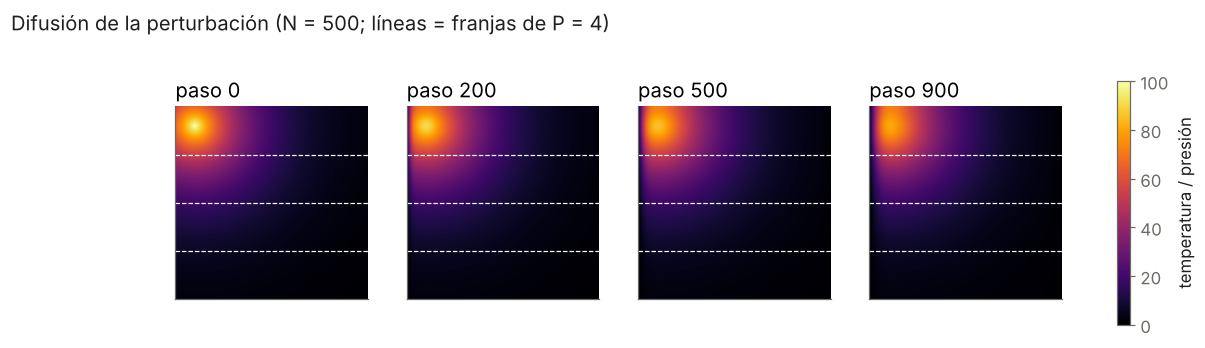

In [8]:
# Evolución de la perturbación (histórico muestreado cada PASOS/10 pasos, con P = 4)
_, _, hist = sm.ejecutar_simulacion(4, N, PASOS, guardar_historico=True)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
vmax = hist[0][1].max()
for a, (paso, campo) in zip(ax, [hist[0], hist[2], hist[5], hist[-1]]):
    im = a.imshow(campo, cmap="inferno", vmin=0, vmax=vmax)
    a.set_title(f"paso {paso}", loc="left"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    for i in range(1, 4):
        a.axhline(i * N / 4, color="white", lw=0.8, ls="--")
fig.colorbar(im, ax=ax, shrink=0.8, label="temperatura / presión")
fig.suptitle(f"Difusión de la perturbación (N = {N}; líneas = franjas de P = 4)",
             x=0.01, ha="left", color=TINTA)
plt.show()

## Tabla de evaluación

* **T_P**: tiempo total con P procesos (mediana de 3 corridas).
* **Aceleración** S_P = T₁ / T_P · **Eficiencia** E_P = S_P / P.
* Se agregan el tiempo máximo de **cómputo** y de **comunicación** entre procesos. La
  comunicación incluye la espera en `recv()` mientras el vecino termina su cálculo.

In [9]:
def tabla_evaluacion(n, pasos, g=1):
    filas = []
    for P in PROCESOS:
        m = medir(P, n, pasos, g=g)
        filas.append({"Procesos (P)": P, "Tiempo total T_P (s)": m["t_total"],
                      "Cómputo máx. (s)": max(x["t_comp"] for x in m["por_proceso"]),
                      "Comunicación máx. (s)": max(x["t_com"] for x in m["por_proceso"])})
    df = pd.DataFrame(filas)
    df["Aceleración (S_P = T1/T_P)"] = df.iloc[0, 1] / df["Tiempo total T_P (s)"]
    df["Eficiencia (E_P = S_P/P)"] = df["Aceleración (S_P = T1/T_P)"] / df["Procesos (P)"]
    return df

def mostrar(df):
    d = df.copy()
    d["Procesos (P)"] = d["Procesos (P)"].map(lambda p: "1 (Secuencial)" if p == 1 else str(p))
    return d.style.format({**{c: "{:.3f}" for c in d.columns if "(s)" in c},
                           "Aceleración (S_P = T1/T_P)": "{:.2f}",
                           "Eficiencia (E_P = S_P/P)": "{:.0%}"}).hide(axis="index")

tabla = tabla_evaluacion(N, PASOS)
tabla.to_csv("tabla_evaluacion.csv", index=False)
print(f"N = {N}, {PASOS} pasos, g = 1")
mostrar(tabla)

N = 500, 1000 pasos, g = 1


Procesos (P),Tiempo total T_P (s),Cómputo máx. (s),Comunicación máx. (s),Aceleración (S_P = T1/T_P),Eficiencia (E_P = S_P/P)
1 (Secuencial),1.173,1.167,0.002,1.00,100%
2,0.785,0.536,0.235,1.49,75%
4,0.819,0.251,0.566,1.43,36%
8,1.153,0.168,0.960,1.02,13%


In [10]:
# Comparación con una malla más fina: más cálculo por cada fila enviada
tabla_1000 = tabla_evaluacion(1000, PASOS // 4)
print(f"N = 1000, {PASOS // 4} pasos, g = 1")
mostrar(tabla_1000)

N = 1000, 250 pasos, g = 1


Procesos (P),Tiempo total T_P (s),Cómputo máx. (s),Comunicación máx. (s),Aceleración (S_P = T1/T_P),Eficiencia (E_P = S_P/P)
1 (Secuencial),1.132,1.122,0.001,1.00,100%
2,0.671,0.543,0.106,1.69,84%
4,0.806,0.347,0.464,1.40,35%
8,0.733,0.148,0.554,1.54,19%


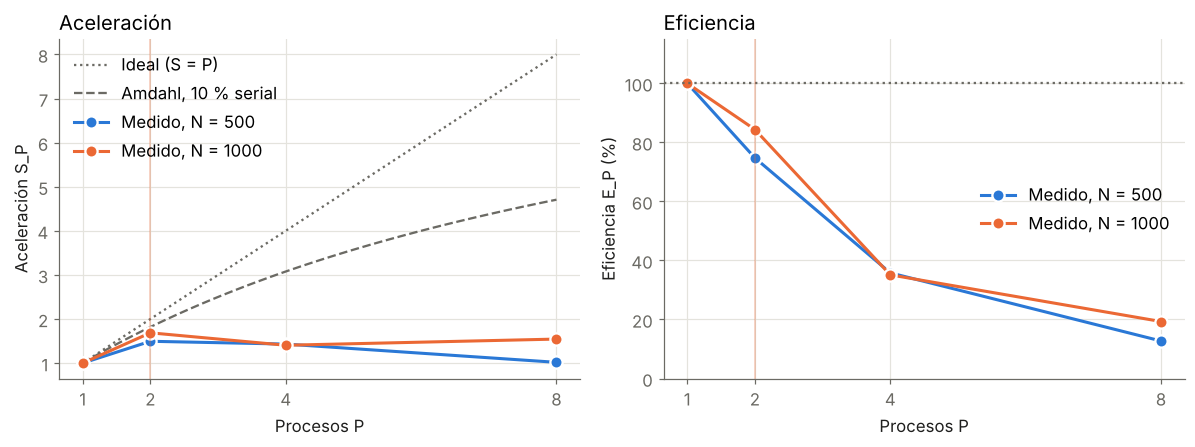

In [11]:
amdahl = lambda p, f: 1 / (f + (1 - f) / p)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
pp = np.linspace(1, 8, 100)
ax[0].plot(pp, pp, color=TINTA_2, ls=":", lw=1.5, label="Ideal (S = P)")
ax[0].plot(pp, amdahl(pp, 0.10), color=TINTA_2, ls="--", lw=1.5, label="Amdahl, 10 % serial")
for df, color, et in ((tabla, AZUL, f"N = {N}"), (tabla_1000, NARANJA, "N = 1000")):
    estilo = dict(color=color, lw=2, marker="o", ms=8, mec="white", mew=1.5, label=f"Medido, {et}")
    ax[0].plot(df["Procesos (P)"], df["Aceleración (S_P = T1/T_P)"], **estilo)
    ax[1].plot(df["Procesos (P)"], 100 * df["Eficiencia (E_P = S_P/P)"], **estilo)
ax[0].set(xlabel="Procesos P", ylabel="Aceleración S_P", xticks=PROCESOS)
ax[0].set_title("Aceleración", loc="left")
ax[1].axhline(100, color=TINTA_2, ls=":", lw=1.5)
ax[1].set(xlabel="Procesos P", ylabel="Eficiencia E_P (%)", xticks=PROCESOS, ylim=(0, 115))
ax[1].set_title("Eficiencia", loc="left")
for a in ax:
    a.legend(frameon=False)
    if NUCLEOS < 8: a.axvline(NUCLEOS, color=NARANJA, lw=1, alpha=0.35)
fig.tight_layout(); fig.savefig("grafica_aceleracion_eficiencia.png", dpi=150); plt.show()

## Pregunta 1 — Ancho de la franja de Ghost Cells con N = 500

Con P = 4 se varía el ancho **g** de la franja enviada por los pipes. Con ancho g:

* se envía un mensaje **cada g pasos**, así que hay g veces menos mensajes;
* cada mensaje mide **g × (N + 2) × 8 bytes** (≈ 4 KB × g con N = 500), así que el
  **volumen total enviado es el mismo**;
* cada proceso **recalcula** ≈ (g − 1) filas extra por paso, que ya calcula su vecino.

Para ver el efecto de la resolución se compara con una malla gruesa (N = 100).

In [12]:
ANCHOS = [1, 2, 4, 8, 16]
filas = []
for n, pasos in ((100, 8000), (N, PASOS)):
    for g in ANCHOS:
        m = medir(4, n, pasos, g=g)
        pr = m["por_proceso"]
        filas.append({"N": n, "g": g, "T total (s)": m["t_total"],
                      "Comunicación máx. (s)": max(x["t_com"] for x in pr),
                      "Cómputo máx. (s)": max(x["t_comp"] for x in pr),
                      "Mensajes por proceso": max(x["mensajes"] for x in pr),
                      "KB por mensaje": g * (n + 2) * 8 / 1024,
                      "MB enviados (total)": sum(x["bytes"] for x in pr) / 2**20,
                      "Cálculo redundante (%)": 100 * (g - 1) / (n / 4)})
ghost = pd.DataFrame(filas)
ghost["T / T(g=1)"] = ghost["T total (s)"] / ghost.groupby("N")["T total (s)"].transform("first")
ghost.to_csv("tabla_ghost_cells.csv", index=False)
ghost.style.format(precision=3).hide(axis="index")

N,g,T total (s),Comunicación máx. (s),Cómputo máx. (s),Mensajes por proceso,KB por mensaje,MB enviados (total),Cálculo redundante (%),T / T(g=1)
100,1,1.850,1.645,0.214,16000,0.797,37.354,0.000,1.000
100,2,1.015,0.834,0.178,8000,1.594,37.354,4.000,0.549
100,4,0.797,0.624,0.174,4000,3.188,37.354,12.000,0.431
100,8,0.548,0.380,0.162,2000,6.375,37.354,28.000,0.296
100,16,0.532,0.349,0.188,1000,12.750,37.354,60.000,0.288
500,1,0.858,0.585,0.257,2000,3.922,22.980,0.000,1.000
500,2,0.684,0.420,0.262,1000,7.844,22.980,0.800,0.797
500,4,0.620,0.374,0.257,500,15.688,22.980,2.400,0.723
500,8,0.638,0.367,0.299,250,31.375,22.980,5.600,0.744
500,16,0.619,0.323,0.389,126,62.750,23.164,12.000,0.722


N = 100: mejor ancho g = 16 → 71 % menos tiempo que con g = 1  |  con g = 16: +71 %
N = 500: mejor ancho g = 16 → 28 % menos tiempo que con g = 1  |  con g = 16: +28 %


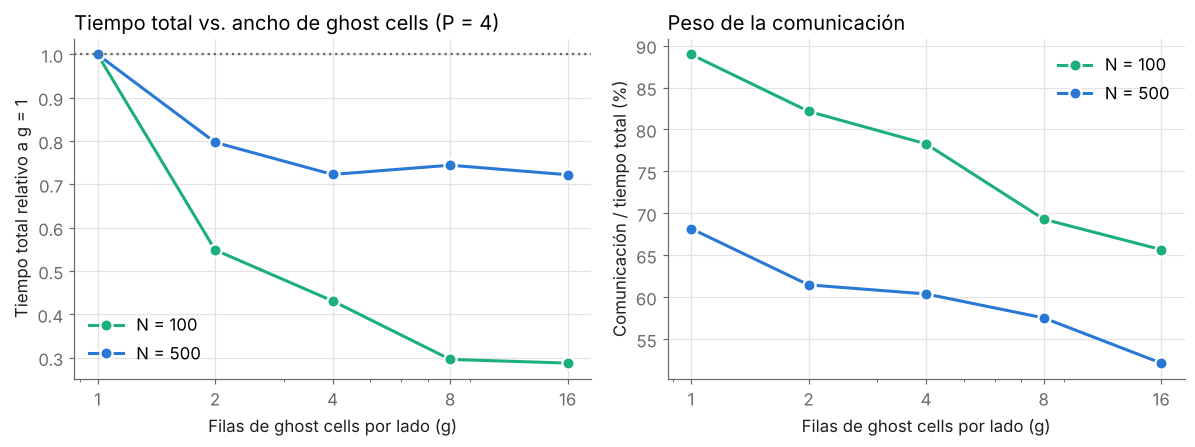

In [13]:
for n in (100, N):
    d = ghost[ghost.N == n].set_index("g")["T / T(g=1)"]
    print(f"N = {n:>3}: mejor ancho g = {d.idxmin():>2} → {100 * (1 - d.min()):.0f} % menos tiempo "
          f"que con g = 1  |  con g = 16: {100 * (1 - d[16]):+.0f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n, color in ((100, VERDE), (N, AZUL)):
    d = ghost[ghost.N == n]
    estilo = dict(color=color, lw=2, marker="o", ms=8, mec="white", mew=1.5, label=f"N = {n}")
    ax[0].plot(d.g, d["T / T(g=1)"], **estilo)
    ax[1].plot(d.g, 100 * d["Comunicación máx. (s)"] / d["T total (s)"], **estilo)
ax[0].axhline(1, color=TINTA_2, ls=":", lw=1.5)
ax[0].set(ylabel="Tiempo total relativo a g = 1")
ax[0].set_title("Tiempo total vs. ancho de ghost cells (P = 4)", loc="left")
ax[1].set(ylabel="Comunicación / tiempo total (%)")
ax[1].set_title("Peso de la comunicación", loc="left")
for a in ax:
    a.set(xscale="log", xticks=ANCHOS, xlabel="Filas de ghost cells por lado (g)")
    a.set_xticklabels(ANCHOS); a.legend(frameon=False)
fig.tight_layout(); fig.savefig("grafica_ghost_cells.png", dpi=150); plt.show()

## Pregunta 2 — Tormenta severa en un subdominio

La tormenta ocupa las filas 5 %–22 % de la malla, que con P = 4 caen **completas en la
franja del proceso 0**. En esas celdas la convección se resuelve con 8 sub-iteraciones.

* **Estática**: franjas iguales de N/P filas.
* **Balanceada por costo**: se hace como un balanceador dinámico. (1) Se **mide** el tiempo
  de cómputo de cada proceso en la corrida estática, (2) con eso se estima cuánto cuesta una
  celda de tormenta frente a una normal y (3) se **reparticiona**, moviendo los cortes para
  que cada proceso reciba el mismo costo.

In [14]:
SUB = 8
m_sec = medir(1, N, PASOS, zona_tormenta=ZONA_TORMENTA, sub_pasos=SUB)

# (1) Corrida estática y (2) estimación del costo de una celda de tormenta
m_est = medir(4, N, PASOS, zona_tormenta=ZONA_TORMENTA, sub_pasos=SUB)
tc = [x["t_comp"] for x in m_est["por_proceso"]]
celdas_franja = (N // 4) * N
costo_normal = statistics.mean(tc[1:]) / celdas_franja          # procesos sin tormenta
f0, f1, c0, c1 = (int(round(z * N)) for z in ZONA_TORMENTA)
celdas_tormenta = (f1 - f0) * (c1 - c0)
peso = (tc[0] - costo_normal * celdas_franja) / celdas_tormenta / costo_normal
print(f"Una celda de tormenta cuesta ≈ {peso + 1:.0f}× una celda normal")

# (3) Reparticionamiento por costo
estrategias = {"Estática (franjas iguales)": None,
               "Balanceada por costo": sm.particion_por_costo(N, 4, ZONA_TORMENTA, peso)}
filas, carga = [], {}
for nombre, franjas in estrategias.items():
    m = m_est if franjas is None else medir(4, N, PASOS, zona_tormenta=ZONA_TORMENTA,
                                            sub_pasos=SUB, franjas=franjas)
    tc = [x["t_comp"] for x in m["por_proceso"]]
    carga[nombre] = tc
    filas.append({"Estrategia": nombre,
                  "Filas por proceso": [f[1] for f in franjas] if franjas else [N // 4] * 4,
                  "T total (s)": m["t_total"], "Aceleración vs. T1": m_sec["t_total"] / m["t_total"],
                  "Desbalance (máx/media)": max(tc) / statistics.mean(tc)})
tormenta = pd.DataFrame(filas)
tormenta.to_csv("tabla_tormenta.csv", index=False)
print(f"T1 secuencial con tormenta: {m_sec['t_total']:.3f} s")
tormenta.style.format(precision=2).hide(axis="index")

Una celda de tormenta cuesta ≈ 46× una celda normal


T1 secuencial con tormenta: 5.385 s


Estrategia,Filas por proceso,T total (s),Aceleración vs. T1,Desbalance (máx/media)
Estática (franjas iguales),"[125, 125, 125, 125]",4.97,1.08,3.37
Balanceada por costo,"[50, 26, 26, 398]",4.41,1.22,1.06


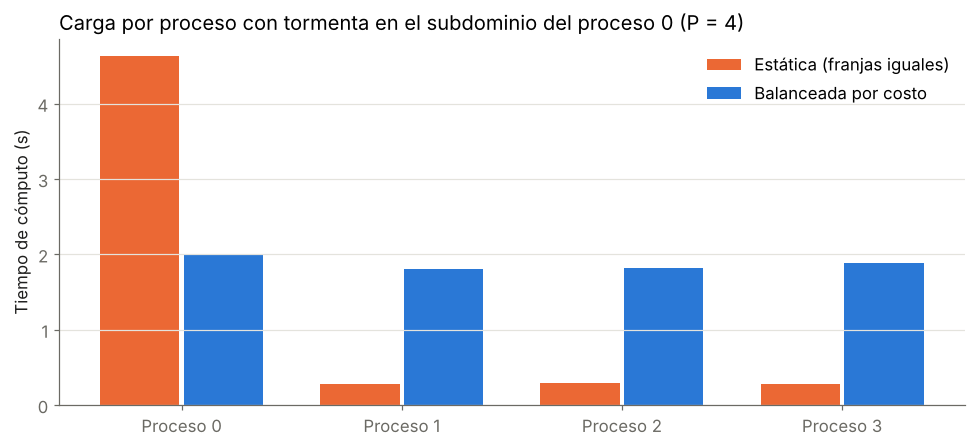

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x, w = np.arange(4), 0.38
for i, (nombre, color) in enumerate(zip(carga, (NARANJA, AZUL))):
    ax.bar(x + (i - 0.5) * w, carga[nombre], w - 0.02, color=color, label=nombre)
ax.set(xticks=x, xticklabels=[f"Proceso {i}" for i in x], ylabel="Tiempo de cómputo (s)")
ax.set_title("Carga por proceso con tormenta en el subdominio del proceso 0 (P = 4)", loc="left")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("grafica_tormenta.png", dpi=150); plt.show()

Con la asignación estática, el proceso 0 hace casi todo el trabajo extra y los demás
terminan antes y esperan en `recv()`. Con el reparto por costo, las barras quedan parejas.
*(Si el equipo tiene menos núcleos que procesos, las barras balanceadas se ven más altas
porque los procesos comparten CPU. Lo que importa es que queden parejas y que baje
T total.)*

## Pregunta 3 — Ley de Amdahl con 10 % de comunicación inalterable

$$S(P) = \frac{1}{f + \frac{1-f}{P}} \qquad\Rightarrow\qquad
S_{\max} = \lim_{P\to\infty} S(P) = \frac{1}{f} = \frac{1}{0.10} = \mathbf{10}$$

In [16]:
f = 0.10
ps = [1, 2, 4, 8, 16, 64, 1024]
pd.DataFrame({"P": [str(p) for p in ps] + ["∞"],
              "S(P) teórica": [amdahl(p, f) for p in ps] + [1 / f],
              "Eficiencia teórica": [amdahl(p, f) / p for p in ps] + [0.0]}
            ).style.format({"S(P) teórica": "{:.2f}", "Eficiencia teórica": "{:.0%}"}).hide(axis="index")

P,S(P) teórica,Eficiencia teórica
1,1.00,100%
2,1.82,91%
4,3.08,77%
8,4.71,59%
16,6.40,40%
64,8.77,14%
1024,9.91,1%
∞,10.00,0%


In [17]:
# Fracción serial efectiva de NUESTRAS mediciones (métrica de Karp-Flatt)
for nombre, df in ((f"N = {N}", tabla), ("N = 1000", tabla_1000)):
    print(nombre)
    for _, r in df.iloc[1:].iterrows():
        p, s = int(r["Procesos (P)"]), r["Aceleración (S_P = T1/T_P)"]
        e = (1 / s - 1 / p) / (1 - 1 / p)
        if e > 0:
            print(f"  P = {p}: S = {s:.2f} → fracción serial ≈ {e:.0%} → techo ≈ {1 / e:.1f}×")
        else:
            print(f"  P = {p}: S = {s:.2f} → superlineal (la franja cabe mejor en caché)")

N = 500
  P = 2: S = 1.49 → fracción serial ≈ 34% → techo ≈ 3.0×
  P = 4: S = 1.43 → fracción serial ≈ 60% → techo ≈ 1.7×
  P = 8: S = 1.02 → fracción serial ≈ 98% → techo ≈ 1.0×
N = 1000
  P = 2: S = 1.69 → fracción serial ≈ 19% → techo ≈ 5.4×
  P = 4: S = 1.40 → fracción serial ≈ 62% → techo ≈ 1.6×
  P = 8: S = 1.54 → fracción serial ≈ 60% → techo ≈ 1.7×


## Respuestas

### 1. ¿Cómo afecta el tamaño de la franja de Ghost Cells al tiempo total con N = 500?

El ancho g mueve dos costos en sentidos opuestos:

* **Comunicación.** Cada intercambio por el pipe tiene un costo fijo: serializar el
  arreglo, la llamada al sistema y, sobre todo, **sincronizarse con el vecino**. Con franja
  g hay g veces menos intercambios. El volumen total de bytes es el mismo (g filas cada g
  pasos = 1 fila por paso), así que lo que se ahorra es **latencia y esperas**, no ancho de
  banda.
* **Cálculo redundante.** Entre intercambios, cada proceso recalcula ≈ (g − 1) filas extra
  por paso. Con N = 500 y P = 4 (125 filas por proceso), g = 16 implica ≈ 12 % más trabajo,
  y cada fila extra cuesta 500 celdas en lugar de 100.

**Al subir a N = 500** el cálculo por proceso crece como N²/P y la comunicación por paso
solo como N (relación superficie/volumen ≈ 2P/N). La comunicación pesa una fracción menor
del tiempo, así que ensanchar la franja **reduce menos el tiempo** que con N = 100 (ver la
gráfica). En ambos casos la mejora **se agota**: a partir de cierto ancho el tiempo deja de
bajar (se aplana o incluso sube), porque el cálculo redundante crece con g mientras que el
ahorro en mensajes es cada vez menor. Con N = 500 ese punto llega antes que con N = 100,
así que una franja angosta o moderada es suficiente. Además,
con N = 500 una franja de g ≥ 16 filas supera los ≈ 64 KB del búfer del pipe. Con el
esquema original (todos envían y luego reciben) eso **bloquea la simulación**; por eso se
usa el orden par/impar.

### 2. Tormenta en un subdominio: ¿por qué falla la asignación estática y qué hacer?

La asignación estática reparte **filas**, no **trabajo**: supone que todas las celdas
cuestan lo mismo. Con la tormenta, el proceso 0 tarda varias veces más que los demás. Como
el ciclo SPMD es **síncrono** (en cada intercambio de ghost cells un proceso no puede
avanzar sin los bordes de su vecino), todos avanzan al ritmo del más lento: el tiempo total
es max(tᵢ) en vez del promedio, y los demás procesos pasan la mayor parte del tiempo
bloqueados en `recv()`. La columna *Desbalance (máx/media)* lo cuantifica.

**Alternativa: balanceo dinámico de carga.**

1. **Medir** cada R pasos el tiempo de cómputo de cada proceso (ya se registra `t_comp`).
2. Si el desbalance supera un umbral (p. ej. 10 %), **mover los cortes de las franjas**
   para igualar el costo y no el número de filas, como hace `particion_por_costo`. Los
   vecinos se transfieren por el mismo pipe las filas que cambian de dueño.
3. Como la tormenta **se desplaza**, el reparto se recalcula periódicamente. Alternativas
   más generales:
   * **difusivo**: cada proceso cede filas al vecino menos cargado;
   * **sobre-descomposición con cola de tareas / *work stealing***: muchos bloques
     pequeños que los procesos toman conforme se liberan;
   * **particionado con curvas de llenado de espacio** (Hilbert) o grafos ponderados
     (ParMETIS/Zoltan), habituales en modelos meteorológicos con refinamiento adaptativo.

Rebalancear tiene un costo (medir y mover datos), así que se hace cada cierto número de
pasos y no en cada uno.

### 3. Ley de Amdahl con 10 % de comunicación inalterable

Con f = 0.10, S(P) = 1 / (0.10 + 0.90 / P). Cuando P → ∞ el término 0.90/P desaparece y
**S_max = 1 / 0.10 = 10×**, sin importar cuántos procesadores se agreguen. Con 8 procesos se
obtiene 4.71× (59 % de eficiencia) y con 64, apenas 8.77×. Para superar ese techo hay que
reducir la parte serial: **solapar comunicación y cálculo** (calcular el interior de la
franja mientras viajan las ghost cells), agrupar mensajes (g > 1) o **aumentar el
tamaño del problema**. Esto último es la ley de Gustafson: con N más grande la comunicación
pesa menos, como muestra la tabla de N = 1000 frente a N = 500.

## Conclusión

Con las correcciones, el código base produce una simulación paralela **idéntica** a la
secuencial. La aceleración está limitada por tres factores medidos en este cuaderno: el
costo fijo de crear procesos y comunicar por pipes (que pesa menos cuanto mayor es N), el
desbalance de carga cuando la física no es uniforme (tormenta) y la fracción no
paralelizable que fija el techo de Amdahl. El ancho de las ghost cells permite cambiar
latencia por cálculo redundante, y cuando la carga es heterogénea el reparto debe seguir
al trabajo y no a la geometría.